In [29]:

# Select numerical features for clustering

features = [
    "Age",
    "Orders_Per_Month",
    "Average_Order_Value",
    "Tenure_Months"
]

X = df[features].copy()

# Check missing values
print("Missing Values Before Preprocessing:")
print(X.isnull().sum())

# Handle missing values using median
X = X.fillna(X.median())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeature selection and preprocessing completed!")


Missing Values Before Preprocessing:
Age                    0
Orders_Per_Month       0
Average_Order_Value    0
Tenure_Months          0
dtype: int64

Feature selection and preprocessing completed!


In [30]:

print("===== PREPROCESSING OUTPUT =====")

print("Total Records:", X.shape[0])
print("Selected Features:", X.shape[1])

print("\nSelected Feature Names:")
print(features)

print("\nMissing Values After Preprocessing:")
print(X.isnull().sum().sum())

print("\nStandardized Dataset Shape:")
print(X_scaled.shape)

print("\nFirst 5 Standardized Records:")
print(pd.DataFrame(X_scaled, columns=features).head())


===== PREPROCESSING OUTPUT =====
Total Records: 500
Selected Features: 4

Selected Feature Names:
['Age', 'Orders_Per_Month', 'Average_Order_Value', 'Tenure_Months']

Missing Values After Preprocessing:
0

Standardized Dataset Shape:
(500, 4)

First 5 Standardized Records:
        Age  Orders_Per_Month  Average_Order_Value  Tenure_Months
0  1.334884         -1.497225            -1.776060      -1.558099
1  0.525569         -0.448013             0.191315      -1.027205
2 -0.607472          0.426330             0.375651       0.489636
3  1.658610          0.426330            -1.481121       1.399741
4 -1.173992         -1.672093            -0.609712       0.565478


In [31]:

# Calculate inertia for different K values

inertia_values = []
k_values = range(1, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

print("Inertia calculated for K = 1 to 10")
print(inertia_values)


Inertia calculated for K = 1 to 10
[2000.0000000000007, 1609.0977167207332, 1353.646756599704, 1166.0862257194017, 1012.0792045362091, 915.3085916564697, 815.583245741192, 730.009998639178, 681.7436801684798, 638.834776252508]


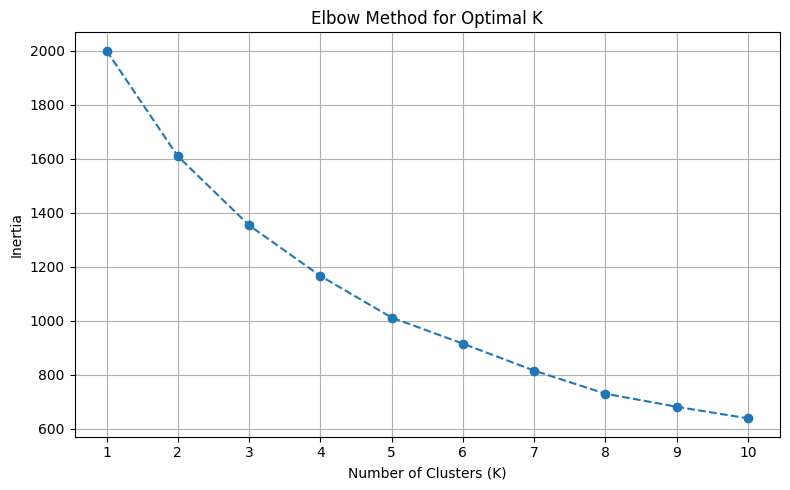

In [32]:

# Plot Elbow Method graph

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker='o',
    linestyle='--'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()


In [33]:

# Apply K-Means clustering with K = 3

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and predict cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to original dataset
df["Cluster"] = cluster_labels

print("K-Means clustering completed successfully!")


K-Means clustering completed successfully!


In [34]:

# Display cluster counts

print("===== NUMBER OF CUSTOMERS IN EACH CLUSTER =====")

print(df["Cluster"].value_counts().sort_index())

# Display cluster centroids
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features
)

print("\n===== STANDARDIZED CLUSTER CENTROIDS =====")
print(centroids.round(3))


===== NUMBER OF CUSTOMERS IN EACH CLUSTER =====
Cluster
0    184
1    164
2    152
Name: count, dtype: int64

===== STANDARDIZED CLUSTER CENTROIDS =====
     Age  Orders_Per_Month  Average_Order_Value  Tenure_Months
0  0.308            -0.197                0.416         -0.914
1  0.400            -0.533               -0.643          0.596
2 -0.805             0.814                0.190          0.463


In [35]:

# Calculate clustering evaluation metrics

sil_score = silhouette_score(
    X_scaled,
    cluster_labels
)

inertia = kmeans.inertia_

db_index = davies_bouldin_score(
    X_scaled,
    cluster_labels
)

print("===== CLUSTERING EVALUATION =====")

print("Number of Clusters:", 3)

print("Silhouette Score:", round(sil_score, 4))

print("Inertia:", round(inertia, 4))

print("Davies-Bouldin Index:", round(db_index, 4))


===== CLUSTERING EVALUATION =====
Number of Clusters: 3
Silhouette Score: 0.1869
Inertia: 1353.6468
Davies-Bouldin Index: 1.6517


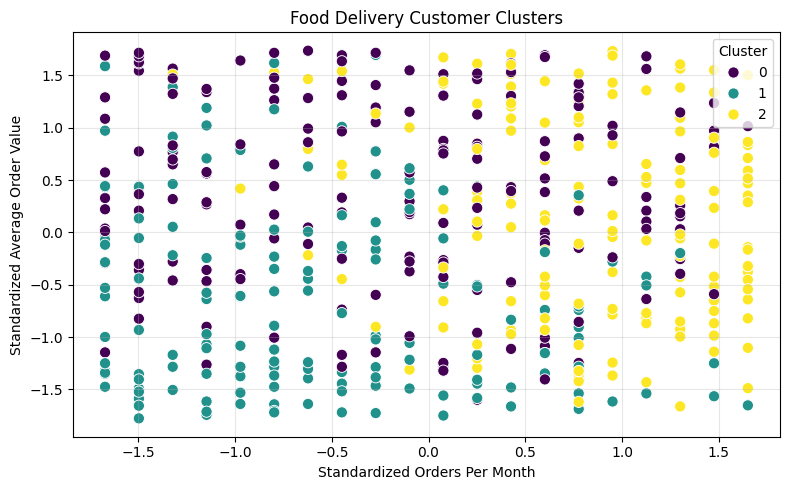

In [36]:

# Prepare data for cluster visualization

plot_data = pd.DataFrame(
    X_scaled,
    columns=features
)

plot_data["Cluster"] = cluster_labels

# Create scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_data,
    x="Orders_Per_Month",
    y="Average_Order_Value",
    hue="Cluster",
    palette="viridis",
    s=65
)

plt.title("Food Delivery Customer Clusters")
plt.xlabel("Standardized Orders Per Month")
plt.ylabel("Standardized Average Order Value")

plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [37]:

# Create dataset with cluster labels

clustered_data = X.copy()

clustered_data["Cluster"] = cluster_labels

# Calculate mean of each feature
cluster_means = clustered_data.groupby(
    "Cluster"
)[features].mean()

# Calculate number of customers
cluster_sizes = clustered_data.groupby(
    "Cluster"
).size()

# Combine results
cluster_summary = cluster_means.copy()

cluster_summary["Number_of_Customers"] = cluster_sizes

print("Cluster-wise analysis completed successfully!")


Cluster-wise analysis completed successfully!


In [38]:

print("===== CLUSTER-WISE CUSTOMER ANALYSIS =====")

print(cluster_summary.round(2))


===== CLUSTER-WISE CUSTOMER ANALYSIS =====
           Age  Orders_Per_Month  Average_Order_Value  Tenure_Months  \
Cluster                                                                
0        43.32              9.43               804.90          12.49   
1        44.45              7.51               489.13          32.40   
2        29.56             15.22               737.76          30.65   

         Number_of_Customers  
Cluster                       
0                        184  
1                        164  
2                        152  


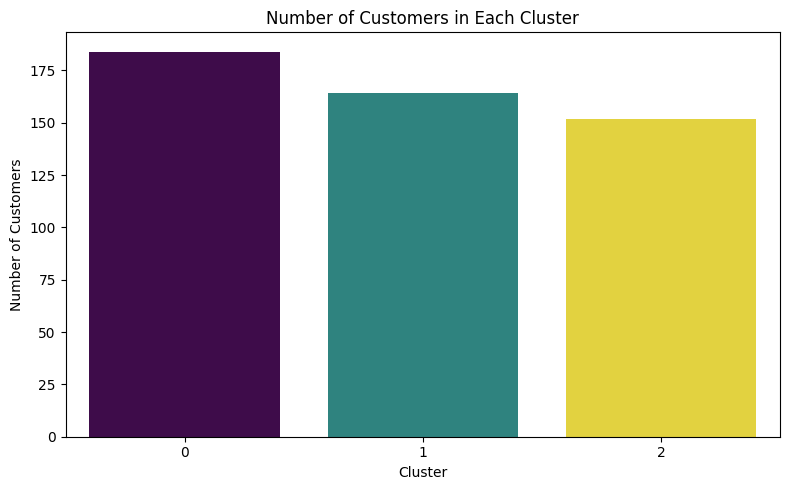

In [39]:

# Plot cluster sizes

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [40]:

# Final K-Means evaluation summary

print("===== FINAL K-MEANS EVALUATION SUMMARY =====")

print("\nNumber of Clusters:", kmeans.n_clusters)

print("Total Customers:", len(df))

print("Silhouette Score:", round(
    silhouette_score(X_scaled, cluster_labels), 4
))

print("Inertia:", round(kmeans.inertia_, 4))

print("Davies-Bouldin Index:", round(
    davies_bouldin_score(X_scaled, cluster_labels), 4
))

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nK-Means Clustering Completed Successfully!")


===== FINAL K-MEANS EVALUATION SUMMARY =====

Number of Clusters: 3
Total Customers: 500
Silhouette Score: 0.1869
Inertia: 1353.6468
Davies-Bouldin Index: 1.6517

Cluster Distribution:
Cluster
0    184
1    164
2    152
Name: count, dtype: int64

K-Means Clustering Completed Successfully!
